# Maladie rénale chronique : profils des patients et facteurs déterminants

Base de 400 patients décrits par 26 variables biologiques et cliniques. L'analyse comprend la préparation des données, la classification ascendante hiérarchique (CAH) des patients, la description des profils obtenus (consigne 1) et l'étude des facteurs déterminants (consigne 2).

## 1. Préparation des données

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist
from scipy.stats import chi2_contingency, fisher_exact, kruskal
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

CHEMIN = "../data/kidney_clean_imputed.csv"
K = 3
SEED = 0

# variables du clustering : mesures biologiques uniquement
BASE = ["age", "bp", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc", "sg", "al"]
LOG = ["sc", "bu", "bgr", "wc"]

### 1.1 Chargement et nettoyage

Les modalités des variables qualitatives sont débarrassées des espaces et tabulations parasites. Pour `rbc` et `pc`, la modalité `unknown` correspond à une information absente : elle est convertie en valeur manquante afin de ne pas être traitée comme une catégorie.

In [2]:
df = pd.read_csv(CHEMIN)
if "id" in df.columns:
    df = df.set_index("id")

for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype(str).str.strip().replace({"nan": np.nan, "?": np.nan, "": np.nan})
df[["rbc", "pc"]] = df[["rbc", "pc"]].replace("unknown", np.nan)

NUM = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]
for c in NUM:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print(df.shape)
for c in ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane", "classification"]:
    print(f"{c:15s}", df[c].value_counts(dropna=False).to_dict())

(400, 25)
rbc             {'normal': 201, nan: 152, 'abnormal': 47}
pc              {'normal': 259, 'abnormal': 76, nan: 65}
pcc             {'notpresent': 358, 'present': 42}
ba              {'notpresent': 378, 'present': 22}
htn             {'no': 253, 'yes': 147}
dm              {'no': 263, 'yes': 137}
cad             {'no': 366, 'yes': 34}
appet           {'good': 318, 'poor': 82}
pe              {'no': 324, 'yes': 76}
ane             {'no': 340, 'yes': 60}
classification  {'ckd': 250, 'notckd': 150}


In [3]:
manq = df.isna().sum()
manq = manq[manq > 0]
display(pd.DataFrame({"valeurs manquantes": manq, "%": (100 * manq / len(df)).round(1)}))

reste = df[NUM].isna().sum()
if reste.sum() > 0:
    df[NUM] = df[NUM].fillna(df[NUM].median())
    print("Imputation par la médiane :", reste[reste > 0].to_dict())

,valeurs manquantes,%
rbc,152,38.0
pc,65,16.2


### 1.2 Valeurs atypiques

Une créatinine supérieure à 20 mg/dL ou une urée inférieure à 5 mg/dL sont physiologiquement improbables (saisie erronée possible). Ces observations sont identifiées puis conservées : on vérifie en section 2.4 que leur retrait ne modifie pas les clusters.

In [4]:
atypiques = df.index[(df["sc"] > 20) | (df["bu"] < 5)]
display(df.loc[atypiques, ["sc", "bu", "hemo", "classification"]])

,sc,bu,hemo,classification
id,,,,
6,24.0,54.0,12.400000,ckd
21,76.0,180.0,10.900000,ckd
61,32.0,391.0,8.226429,ckd
148,48.1,26.0,12.774520,ckd
173,7.3,1.5,13.100000,ckd


## 2. Classification ascendante hiérarchique

### 2.1 Méthode

- **Variables** : age, bp, bgr, bu, sc, sod, pot, hemo, pcv, wc, rc, sg, al. Ce sont les mesures biologiques, qui décrivent l'état du patient.
- **Variables exclues** : les variables cliniques (`htn`, `dm`, `cad`, `ane`, `pe`, `appet`) et le sucre urinaire (`su`, qui reflète surtout le diabète) servent à interpréter les clusters et à étudier leurs déterminants (consigne 2). Les utiliser aussi pour construire les clusters rendrait cette étude circulaire. `classification` (le diagnostic) n'est utilisée que pour contrôler les résultats.
- **Transformations** : logarithme de `sc`, `bu`, `bgr` et `wc`, dont les distributions sont très asymétriques, puis standardisation, car les variables n'ont pas la même unité (par exemple `wc` en milliers et `sc` en mg/dL).
- **Algorithme** : distance euclidienne et critère de Ward, qui fusionne à chaque étape les deux groupes dont l'union augmente le moins la variance intra-groupe. Il produit des groupes compacts et ne demande aucun paramètre à fixer a priori.

In [5]:
def preparer(cols, data):
    X = data[cols].astype(float).copy()
    for c in LOG:
        if c in X:
            X[c] = np.log1p(X[c])
    return StandardScaler().fit_transform(X)


def cah(cols, k, data=None, method="ward"):
    data = df if data is None else data
    Z = preparer(cols, data)
    L = linkage(Z, method=method)
    return pd.Series(fcluster(L, k, criterion="maxclust"), index=data.index), L, Z


lab, L, Z = cah(BASE, K)
print("Coefficient cophénétique :", round(cophenet(L, pdist(Z))[0], 3))

Coefficient cophénétique : 0.499


### 2.2 Dendrogramme

La hauteur d'une fusion mesure l'écart entre les deux groupes réunis. Couper l'arbre à une hauteur donnée fixe le nombre de clusters.

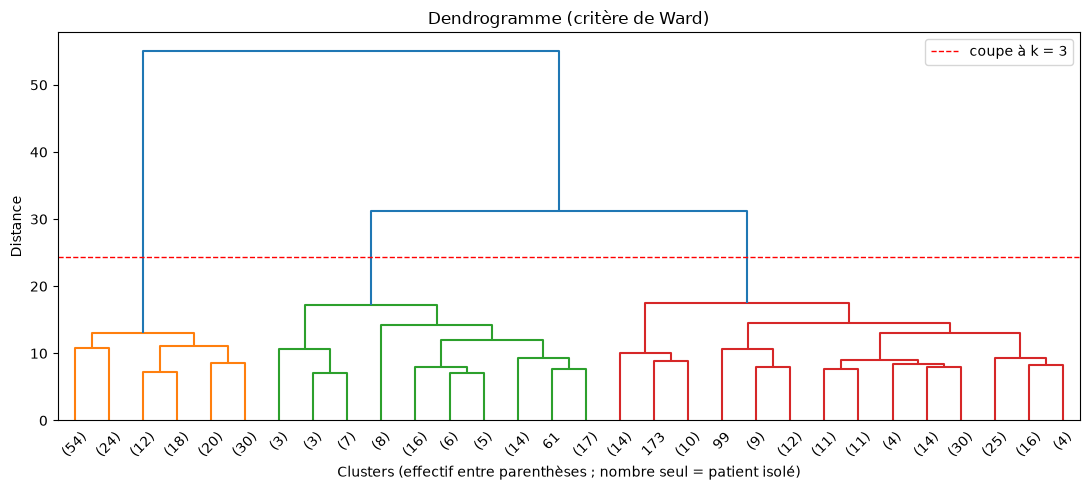

In [6]:
h = L[:, 2]
coupe = (h[-K] + h[-(K - 1)]) / 2

fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(L, truncate_mode="lastp", p=30, ax=ax, color_threshold=coupe)
ax.axhline(coupe, color="red", ls="--", lw=1, label=f"coupe à k = {K}")
ax.grid(False)
ax.set_title("Dendrogramme (critère de Ward)")
ax.set_xlabel("Clusters (effectif entre parenthèses ; nombre seul = patient isolé)")
ax.set_ylabel("Distance")
ax.legend()
plt.tight_layout()
plt.show()

### 2.3 Choix du nombre de clusters

In [7]:
ks = range(2, 7)
rows = []
for k in ks:
    l = fcluster(L, k, criterion="maxclust")
    rows.append({"k": k, "silhouette": round(silhouette_score(Z, l), 3),
                 "écart de hauteur disponible": round(h[-(k - 1)] - h[-k], 1),
                 "effectif du plus petit cluster": int(np.bincount(l)[1:].min())})
display(pd.DataFrame(rows).set_index("k"))

,silhouette,écart de hauteur disponible,effectif du plus petit cluster
k,,,
2,0.251,23.9,158
3,0.201,13.8,80
4,0.189,0.2,25
5,0.196,2.7,13
6,0.175,0.4,13


In [8]:
est_ckd = df["classification"] == "ckd"
for k in range(3, 7):
    l = pd.Series(fcluster(L, k, criterion="maxclust"), index=df.index)
    t = df.groupby(l)[["sc", "bu", "hemo", "pcv", "rc", "al", "sg"]].median()
    t.insert(0, "n", l.value_counts())
    t.insert(1, "% MRC", (100 * est_ckd.groupby(l).mean()).round(0))
    print(f"k = {k} (clusters triés par créatinine médiane)")
    display(t.sort_values("sc").round(2))

k = 3 (clusters triés par créatinine médiane)


,n,% MRC,sc,bu,hemo,pcv,rc,al,sg
1,158,6.0,0.90,32.0,15.0,46.0,5.30,0.0,1.02
3,162,99.0,1.80,46.0,11.6,36.0,4.33,1.0,1.01
2,80,100.0,6.35,107.0,9.1,28.0,3.40,2.0,1.01


k = 4 (clusters triés par créatinine médiane)


,n,% MRC,sc,bu,hemo,pcv,rc,al,sg
1,158,6.0,0.90,32.0,15.00,46.00,5.30,0.0,1.02
4,137,99.0,1.80,45.0,11.51,35.81,4.28,1.0,1.01
3,25,100.0,2.00,46.0,11.80,36.80,4.60,1.0,1.01
2,80,100.0,6.35,107.0,9.10,28.00,3.40,2.0,1.01


k = 5 (clusters triés par créatinine médiane)


,n,% MRC,sc,bu,hemo,pcv,rc,al,sg
1,158,6.0,0.9,32.0,15.00,46.00,5.30,0.0,1.02
5,137,99.0,1.8,45.0,11.51,35.81,4.28,1.0,1.01
4,25,100.0,2.0,46.0,11.80,36.80,4.60,1.0,1.01
2,13,100.0,6.3,58.0,10.09,31.62,3.80,2.0,1.01
3,67,100.0,6.4,111.0,8.80,27.00,3.40,2.0,1.01


k = 6 (clusters triés par créatinine médiane)


,n,% MRC,sc,bu,hemo,pcv,rc,al,sg
1,158,6.0,0.90,32.0,15.00,46.00,5.30,0.0,1.02
6,115,99.0,1.70,42.0,11.69,36.00,4.30,1.0,1.01
4,25,100.0,2.00,46.0,11.80,36.80,4.60,1.0,1.01
5,22,100.0,2.48,51.5,11.20,32.65,4.12,2.0,1.01
2,13,100.0,6.30,58.0,10.09,31.62,3.80,2.0,1.01
3,67,100.0,6.40,111.0,8.80,27.00,3.40,2.0,1.01


La silhouette mesure la séparation des clusters : des valeurs modérées traduisent un continuum de gravité plutôt que des groupes disjoints, ce qui est attendu pour une maladie évolutive. La silhouette favorise **k = 2** (0,25, contre 0,20 pour **k = 3**), mais **k = 3** est retenu pour distinguer deux niveaux d'atteinte rénale — modérée et sévère — en plus du groupe de référence. Ces profils se distinguent nettement par la créatinine, l'urée, l'hémoglobine et l'albuminurie. Les coupes suivantes (k = 4, 5, 6) séparent des groupes de profils très proches, ou isolent un petit nombre de patients, sans apporter de niveau de gravité supplémentaire.

### 2.4 Robustesse

In [9]:
def ari(autre):
    idx = autre.index.intersection(lab.index)
    return adjusted_rand_score(lab.loc[idx], autre.loc[idx])


print(f"ARI sans les observations atypiques : {ari(cah(BASE, K, df.drop(index=atypiques))[0]):.2f}")
print(f"ARI avec su ajoutée au clustering    : {ari(cah(BASE + ['su'], K)[0]):.2f}")

ARI sans les observations atypiques : 0.91
ARI avec su ajoutée au clustering    : 0.86


L'indice de Rand ajusté (ARI) vaut 1 lorsque deux partitions sont identiques. Une valeur élevée indique que les clusters ne dépendent ni des observations atypiques ni du choix d'exclure `su`.

### 2.5 Construction des groupes et contrôle

Les numéros de clusters sont arbitraires : ils sont réordonnés par créatinine médiane croissante (groupe 1 = créatinine la plus basse). `classification` n'est pas utilisée directement dans le clustering, mais elle a participé à l'imputation. Le tableau croisé sert donc de contrôle externe. La variable `pc` comporte 65 valeurs manquantes, soit 16,2 %, et l'accord entre les groupes et la classification est de 0,730.

In [10]:
df["cluster"] = lab
ordre = df.groupby("cluster")["sc"].median().sort_values().index
df["groupe"] = df["cluster"].map({c: i + 1 for i, c in enumerate(ordre)}).astype(int)
Z_df = pd.DataFrame(Z, index=df.index)

display(pd.crosstab(df["groupe"], df["classification"], margins=True))

classification,ckd,notckd,All
groupe,,,
1,9,149,158
2,161,1,162
3,80,0,80
All,250,150,400


## 3. Consigne 1 : description des profils

Chaque cluster est décrit par ses médianes (avec les quartiles) pour les variables quantitatives et par ses fréquences pour les variables qualitatives. Le test de Kruskal-Wallis mesure si une variable diffère entre les clusters, et ε² (= H / (n − 1)) en donne l'ampleur : environ 0,06 pour un écart moyen, 0,14 et plus pour un écart important.

In [11]:
def fp(p):
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")


def f(x, d=1):
    return f"{x:.{d}f}".replace(".", ",")


def cap(s):
    return s[:1].upper() + s[1:]


def liste(x):
    return x[0] if len(x) == 1 else ", ".join(x[:-1]) + " et " + x[-1]


VAR_DESC = [("age", "Âge (ans)", 0), ("bp", "Pression artérielle (mm Hg)", 0), ("bgr", "Glycémie aléatoire (mg/dL)", 0),
            ("bu", "Urée sanguine (mg/dL)", 0), ("sc", "Créatinine sérique (mg/dL)", 1), ("sod", "Sodium (mEq/L)", 0),
            ("pot", "Potassium (mEq/L)", 1), ("hemo", "Hémoglobine (g/dL)", 1), ("pcv", "Hématocrite", 0),
            ("wc", "Globules blancs", 0), ("rc", "Globules rouges", 1), ("sg", "Gravité spécifique", 3),
            ("al", "Albumine urinaire (0 à 5)", 0), ("su", "Sucre urinaire (0 à 5)", 0)]

rows, eps = [], {}
for v, lib, d in VAR_DESC:
    ligne = {"Variable": lib}
    groupes = []
    for s, g in df.groupby("groupe"):
        q1, q2, q3 = g[v].quantile([0.25, 0.5, 0.75])
        ligne[f"Cluster {s} (n = {len(g)})"] = f"{q2:.{d}f} [{q1:.{d}f} – {q3:.{d}f}]"
        groupes.append(g[v].values)
    H, p = kruskal(*groupes)
    eps[v] = H / (len(df) - 1)
    ligne["p"] = fp(p)
    ligne["ε²"] = round(eps[v], 3)
    rows.append(ligne)
tab_num = pd.DataFrame(rows).set_index("Variable")
tab_num

,Cluster 1 (n = 158),Cluster 2 (n = 162),Cluster 3 (n = 80),p,ε²
Variable,,,,,
Âge (ans),45 [34 – 57],60 [47 – 65],58 [50 – 67],"< 0,001",0.104
Pression artérielle (mm Hg),70 [60 – 80],75 [70 – 90],80 [70 – 90],"< 0,001",0.091
Glycémie aléatoire (mg/dL),109 [94 – 125],142 [109 – 220],149 [107 – 213],"< 0,001",0.180
Urée sanguine (mg/dL),32 [23 – 42],46 [28 – 59],107 [76 – 159],"< 0,001",0.428
Créatinine sérique (mg/dL),0.9 [0.7 – 1.1],1.8 [1.3 – 2.7],6.3 [3.9 – 11.8],"< 0,001",0.646
Sodium (mEq/L),141 [138 – 145],137 [135 – 139],134 [130 – 137],"< 0,001",0.318
Potassium (mEq/L),4.4 [3.8 – 4.9],4.3 [4.0 – 4.4],4.8 [4.3 – 5.5],"< 0,001",0.069
Hémoglobine (g/dL),15.0 [14.0 – 16.1],11.6 [10.8 – 12.4],9.1 [7.9 – 10.0],"< 0,001",0.772
Hématocrite,46 [43 – 50],36 [33 – 38],28 [24 – 31],"< 0,001",0.762


In [12]:
CLIN = {"htn": ("Hypertension", "yes"), "dm": ("Diabète", "yes"), "cad": ("Maladie coronarienne", "yes"),
        "ane": ("Anémie", "yes"), "pe": ("Œdème des pieds", "yes"), "appet": ("Appétit mauvais", "poor"),
        "pcc": ("Agrégats de cellules de pus", "present"), "ba": ("Bactéries urinaires", "present"),
        "rbc": ("Globules rouges urinaires anormaux", "abnormal"), "pc": ("Cellules de pus anormales", "abnormal")}

pct = pd.DataFrame({c: ((df[c] == m).astype(float).where(df[c].notna())).groupby(df["groupe"]).mean() * 100
                    for c, (lib, m) in CLIN.items()})
tab_pct = pct.round(1).T
tab_pct.index = [CLIN[c][0] for c in tab_pct.index]
tab_pct.columns = [f"Cluster {s} (n = {n})" for s, n in zip(tab_pct.columns, df["groupe"].value_counts().sort_index())]
print("Pourcentage de patients concernés (pour rbc et pc : parmi les valeurs renseignées)")
tab_pct

Pourcentage de patients concernés (pour rbc et pc : parmi les valeurs renseignées)


,Cluster 1 (n = 158),Cluster 2 (n = 162),Cluster 3 (n = 80)
Hypertension,0.6,51.9,77.5
Diabète,2.5,50.6,63.7
Maladie coronarienne,0.0,9.3,23.8
Anémie,0.0,12.3,50.0
Œdème des pieds,1.3,24.1,43.8
Appétit mauvais,1.3,29.0,41.2
Agrégats de cellules de pus,0.0,14.8,22.5
Bactéries urinaires,0.0,6.8,13.8
Globules rouges urinaires anormaux,0.7,37.9,49.0
Cellules de pus anormales,0.7,30.2,62.1


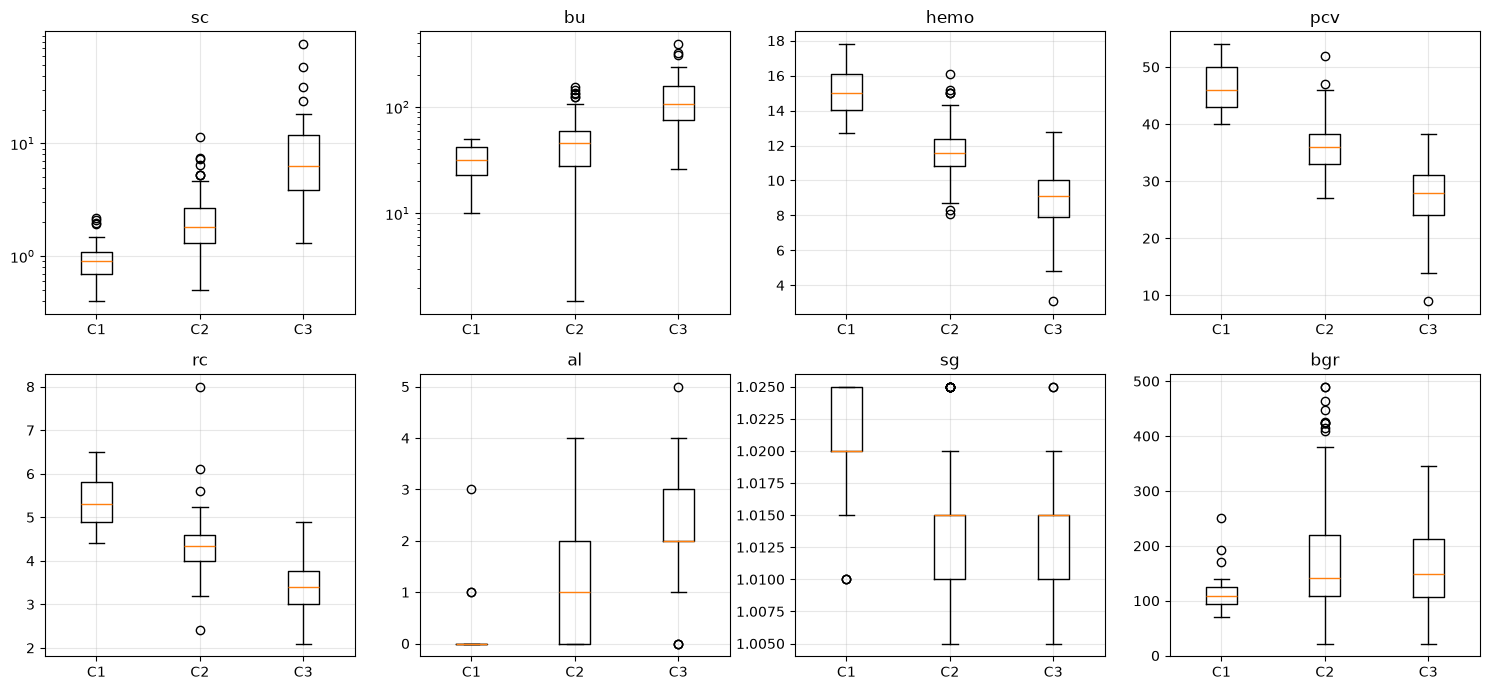

In [13]:
var_box = ["sc", "bu", "hemo", "pcv", "rc", "al", "sg", "bgr"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, v in zip(axes.ravel(), var_box):
    ax.boxplot([g[v].values for _, g in df.groupby("groupe")])
    ax.set_xticklabels([f"C{s}" for s in sorted(df["groupe"].unique())])
    ax.set_title(v)
    if v in ("sc", "bu"):
        ax.set_yscale("log")
plt.tight_layout()
plt.show()

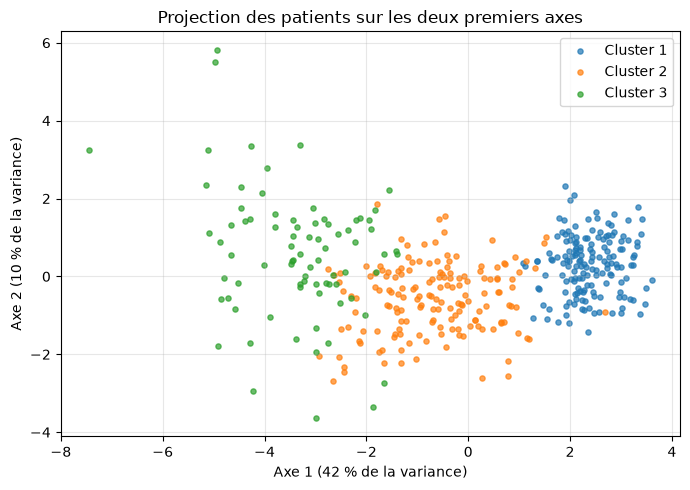

In [14]:
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(7, 5))
for s in sorted(df["groupe"].unique()):
    m = (df["groupe"] == s).values
    ax.scatter(P[m, 0], P[m, 1], s=14, alpha=0.7, label=f"Cluster {s}")
ax.set_xlabel(f"Axe 1 ({100 * pca.explained_variance_ratio_[0]:.0f} % de la variance)")
ax.set_ylabel(f"Axe 2 ({100 * pca.explained_variance_ratio_[1]:.0f} % de la variance)")
ax.set_title("Projection des patients sur les deux premiers axes")
ax.legend()
plt.tight_layout()
plt.show()

### 3.1 Profil de chaque cluster

In [15]:
NOMS = {1: "profil de référence", 2: "atteinte rénale modérée", 3: "atteinte rénale sévère"}
NOMS = {s: NOMS.get(s, f"niveau {s}") for s in df["groupe"].unique()}
med = df.groupby("groupe")[NUM].median()


def decrire(s):
    g = df[df["groupe"] == s]
    m, p, n = med.loc[s], pct.loc[s], len(g)
    pmrc = 100 * (g["classification"] == "ckd").mean()
    t = [f"**Cluster {s} : {NOMS[s]}.** Il regroupe {n} patients ({f(100 * n / len(df), 0)} % de l'échantillon), "
         f"dont {f(pmrc, 0)} % sont classés MRC."]

    # fonction rénale
    r_sc = f" (multipliée par {f(m['sc'] / med.loc[1, 'sc'])} par rapport au cluster 1)" if s > 1 else ""
    r_bu = f" (multipliée par {f(m['bu'] / med.loc[1, 'bu'])})" if s > 1 else ""
    t.append(f"La créatinine sérique médiane est de {f(m['sc'])} mg/dL{r_sc} et l'urée sanguine de {f(m['bu'], 0)} mg/dL{r_bu}.")
    if m["sc"] <= 1.3 and m["bu"] <= 45:
        t.append("Ces valeurs se situent dans les limites usuelles de la fonction rénale.")
    elif m["sc"] <= 3:
        t.append("Ces valeurs traduisent une réduction de la filtration rénale.")
    else:
        t.append("Ces valeurs traduisent une insuffisance rénale avancée.")

    # sang
    if m["hemo"] >= 13:
        q = "dans les valeurs usuelles"
    elif m["hemo"] >= 11:
        q = "compatible avec une anémie légère"
    elif m["hemo"] >= 8:
        q = "témoignant d'une anémie modérée"
    else:
        q = "témoignant d'une anémie sévère"
    t.append(f"L'hémoglobine médiane est de {f(m['hemo'])} g/dL, {q}, avec un hématocrite de {f(m['pcv'], 0)} % "
             f"et {f(m['rc'])} millions de globules rouges.")

    # urine
    q_al = "une absence d'albumine" if m["al"] < 0.5 else "une albuminurie faible" if m["al"] < 1.5 else "une albuminurie marquée"
    q_sg = "peu concentrées" if m["sg"] <= 1.0105 else "normalement concentrées" if m["sg"] >= 1.0195 else "de concentration intermédiaire"
    t.append(f"Sur le plan urinaire, on observe {q_al} (échelle de 0 à 5 : {f(m['al'], 0)}) ; les urines sont {q_sg} (gravité spécifique de {f(m['sg'], 3)}).")

    # clinique
    t.append(f"L'hypertension concerne {f(p['htn'], 0)} % des patients, le diabète {f(p['dm'], 0)} % et la maladie coronarienne "
             f"{f(p['cad'], 0)} %. L'anémie est signalée chez {f(p['ane'], 0)} % des patients, l'œdème des pieds chez "
             f"{f(p['pe'], 0)} % et une altération de l'appétit chez {f(p['appet'], 0)} %.")
    t.append(f"L'âge médian est de {f(m['age'], 0)} ans, la pression artérielle de {f(m['bp'], 0)} mm Hg et la glycémie "
             f"aléatoire de {f(m['bgr'], 0)} mg/dL.")

    # évolution par rapport au cluster précédent
    if s > 1:
        a = med.loc[s - 1]
        t.append(f"Par rapport au cluster {s - 1}, la créatinine est multipliée par {f(m['sc'] / a['sc'])}, l'urée par "
                 f"{f(m['bu'] / a['bu'])} et l'hémoglobine diminue de {f(a['hemo'] - m['hemo'])} g/dL ; la fréquence de "
                 f"l'anémie passe de {f(pct.loc[s - 1, 'ane'], 0)} % à {f(p['ane'], 0)} % et celle de l'œdème des pieds de "
                 f"{f(pct.loc[s - 1, 'pe'], 0)} % à {f(p['pe'], 0)} %.")
    return " ".join(t)


for s in sorted(df["groupe"].unique()):
    display(Markdown(decrire(s)))

**Cluster 1 : profil de référence.** Il regroupe 158 patients (40 % de l'échantillon), dont 6 % sont classés MRC. La créatinine sérique médiane est de 0,9 mg/dL et l'urée sanguine de 32 mg/dL. Ces valeurs se situent dans les limites usuelles de la fonction rénale. L'hémoglobine médiane est de 15,0 g/dL, dans les valeurs usuelles, avec un hématocrite de 46 % et 5,3 millions de globules rouges. Sur le plan urinaire, on observe une absence d'albumine (échelle de 0 à 5 : 0) ; les urines sont normalement concentrées (gravité spécifique de 1,020). L'hypertension concerne 1 % des patients, le diabète 3 % et la maladie coronarienne 0 %. L'anémie est signalée chez 0 % des patients, l'œdème des pieds chez 1 % et une altération de l'appétit chez 1 %. L'âge médian est de 45 ans, la pression artérielle de 70 mm Hg et la glycémie aléatoire de 109 mg/dL.

**Cluster 2 : atteinte rénale modérée.** Il regroupe 162 patients (40 % de l'échantillon), dont 99 % sont classés MRC. La créatinine sérique médiane est de 1,8 mg/dL (multipliée par 2,0 par rapport au cluster 1) et l'urée sanguine de 46 mg/dL (multipliée par 1,4). Ces valeurs traduisent une réduction de la filtration rénale. L'hémoglobine médiane est de 11,6 g/dL, compatible avec une anémie légère, avec un hématocrite de 36 % et 4,3 millions de globules rouges. Sur le plan urinaire, on observe une albuminurie faible (échelle de 0 à 5 : 1) ; les urines sont de concentration intermédiaire (gravité spécifique de 1,015). L'hypertension concerne 52 % des patients, le diabète 51 % et la maladie coronarienne 9 %. L'anémie est signalée chez 12 % des patients, l'œdème des pieds chez 24 % et une altération de l'appétit chez 29 %. L'âge médian est de 60 ans, la pression artérielle de 75 mm Hg et la glycémie aléatoire de 142 mg/dL. Par rapport au cluster 1, la créatinine est multipliée par 2,0, l'urée par 1,4 et l'hémoglobine diminue de 3,4 g/dL ; la fréquence de l'anémie passe de 0 % à 12 % et celle de l'œdème des pieds de 1 % à 24 %.

**Cluster 3 : atteinte rénale sévère.** Il regroupe 80 patients (20 % de l'échantillon), dont 100 % sont classés MRC. La créatinine sérique médiane est de 6,3 mg/dL (multipliée par 7,1 par rapport au cluster 1) et l'urée sanguine de 107 mg/dL (multipliée par 3,3). Ces valeurs traduisent une insuffisance rénale avancée. L'hémoglobine médiane est de 9,1 g/dL, témoignant d'une anémie modérée, avec un hématocrite de 28 % et 3,4 millions de globules rouges. Sur le plan urinaire, on observe une albuminurie marquée (échelle de 0 à 5 : 2) ; les urines sont de concentration intermédiaire (gravité spécifique de 1,015). L'hypertension concerne 78 % des patients, le diabète 64 % et la maladie coronarienne 24 %. L'anémie est signalée chez 50 % des patients, l'œdème des pieds chez 44 % et une altération de l'appétit chez 41 %. L'âge médian est de 58 ans, la pression artérielle de 80 mm Hg et la glycémie aléatoire de 149 mg/dL. Par rapport au cluster 2, la créatinine est multipliée par 3,5, l'urée par 2,3 et l'hémoglobine diminue de 2,5 g/dL ; la fréquence de l'anémie passe de 12 % à 50 % et celle de l'œdème des pieds de 24 % à 44 %.

### 3.2 Synthèse

In [16]:
croiss, decroiss = [], []
LIB = {"sc": "la créatinine", "bu": "l'urée", "hemo": "l'hémoglobine", "pcv": "l'hématocrite", "rc": "les globules rouges",
       "al": "l'albuminurie", "sg": "la gravité spécifique"}
for v in ["sc", "bu", "al", "hemo", "pcv", "rc", "sg"]:
    x = med[v].sort_index().values
    if np.all(np.diff(x) > 0):
        croiss.append(LIB[v])
    elif np.all(np.diff(x) < 0):
        decroiss.append(LIB[v])


def pluriel(x):
    return len(x) > 1 or x[0].startswith("les ")


txt = [f"Les {df['groupe'].nunique()} clusters s'ordonnent selon un gradient de sévérité de l'atteinte rénale."]
a = f"{liste(croiss)} augmente{'nt' if pluriel(croiss) else ''} d'un cluster à l'autre" if croiss else ""
b = f"{liste(decroiss)} diminue{'nt' if pluriel(decroiss) else ''}" if decroiss else ""
if croiss and decroiss:
    txt.append(cap(a) + ", tandis que " + b + ".")
elif croiss:
    txt.append(cap(a) + ".")
elif decroiss:
    txt.append(cap(b) + " d'un cluster à l'autre.")

top = sorted(eps, key=eps.get, reverse=True)[:4]
LIBV = {v: lib for v, lib, d in VAR_DESC}
txt.append("Les écarts les plus marqués entre clusters concernent : " + liste([LIBV[v].split(" (")[0].lower() for v in top]) +
           f" (ε² compris entre {f(eps[top[-1]], 2)} et {f(eps[top[0]], 2)}).")
faibles = [LIBV[v].split(" (")[0].lower() for v in eps if eps[v] < 0.06]
if faibles:
    txt.append("Les variables suivantes distinguent peu les clusters (ε² < 0,06) : " + liste(faibles) + ".")
display(Markdown(" ".join(txt)))

Les 3 clusters s'ordonnent selon un gradient de sévérité de l'atteinte rénale. La créatinine, l'urée et l'albuminurie augmentent d'un cluster à l'autre, tandis que l'hémoglobine, l'hématocrite et les globules rouges diminuent. Les écarts les plus marqués entre clusters concernent : hémoglobine, hématocrite, globules rouges et créatinine sérique (ε² compris entre 0,65 et 0,77). Les variables suivantes distinguent peu les clusters (ε² < 0,06) : globules blancs.

## 4. Consigne 2 : facteurs déterminants

### 4.1 Démarche

- **Variables étudiées** : celles qui n'ont pas servi au clustering, afin d'éviter la circularité. On distingue les **causes** de la MRC (`htn`, `dm`, `cad`), les **symptômes** associés à sa progression (`ane`, `pe`, `appet`) et les marqueurs urinaires (`su`, `rbc`, `pc`, `pcc`, `ba`).
- **Mesure du lien** : le V de Cramér, compris entre 0 et 1, pour les variables qualitatives (autour de 0,1 : lien faible, 0,3 : moyen, 0,5 et plus : fort), et le test de Kruskal-Wallis avec ε² pour `su`, qui est ordinale. Avec 400 patients, la p-value est presque toujours très faible ; l'interprétation repose donc sur la **taille d'effet**. Quand les effectifs théoriques sont inférieurs à 5 dans un tableau 2 × 2, le test exact de Fisher remplace le χ².
- **Deux comparaisons** : (a) entre tous les clusters, qui mesure ce qui distingue les malades des non-malades ; (b) entre les clusters de MRC seulement (clusters 2 et 3), qui mesure ce qui varie avec la sévérité.
- **Lecture** : une variable déjà fréquente dans le cluster d'atteinte modérée, et dont le V est élevé en (a) mais faible en (b), est un **facteur de risque** (liée à la présence de la maladie). Une variable dont le V reste élevé en (b) est un **marqueur de progression** (elle varie avec la sévérité).
- **Classement complémentaire** : une forêt aléatoire, qui donne l'importance relative des variables pour prédire le cluster. Cette importance est descriptive et non causale.

In [17]:
CAT = ["htn", "dm", "cad", "ane", "pe", "appet", "rbc", "pc", "pcc", "ba"]


def v_cramer(tab):
    chi2, p, dof, exp = chi2_contingency(tab)
    n = tab.values.sum()
    v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    low = (exp < 5).mean()
    if tab.shape == (2, 2) and low > 0:
        p = fisher_exact(tab)[1]
    return v, p, low


def intensite(v):
    return "négligeable" if v < 0.1 else "faible" if v < 0.3 else "moyen" if v < 0.5 else "fort"


def analyser(data):
    rows = []
    for c in CAT:
        tab = pd.crosstab(data["groupe"], data[c])
        if min(tab.shape) < 2:
            continue
        v, p, low = v_cramer(tab)
        rows.append({"variable": c, "V de Cramér": round(v, 3), "p": p, "n": int(tab.values.sum()),
                     "effectifs théoriques < 5": f"{100 * low:.0f} %", "lien": intensite(v)})
    return pd.DataFrame(rows).set_index("variable").sort_values("V de Cramér", ascending=False)


def kw_su(data):
    groupes = [g["su"].values for _, g in data.groupby("groupe")]
    H, p = kruskal(*groupes)
    return H / (len(data) - 1), p


tous = df
mrc = df[df["groupe"] > 1]
res_tous, res_mrc = analyser(tous), analyser(mrc)

print("Comparaison entre tous les clusters")
display(res_tous.style.format({"p": fp}))
print("Comparaison entre les clusters de MRC (2 et 3)")
display(res_mrc.style.format({"p": fp}))

e_t, p_t = kw_su(tous)
e_m, p_m = kw_su(mrc)
print(f"Sucre urinaire (su) : ε² = {f(e_t, 3)} (p {fp(p_t)}) entre tous les clusters ; ε² = {f(e_m, 3)} (p {fp(p_m)}) entre les clusters de MRC")

Comparaison entre tous les clusters


,V de Cramér,p,n,effectifs théoriques < 5,lien
variable,,,,,
htn,0.636000,"< 0,001",400,0 %,fort
dm,0.549000,"< 0,001",400,0 %,fort
rbc,0.542000,"< 0,001",248,0 %,fort
pc,0.536000,"< 0,001",335,0 %,fort
ane,0.514000,"< 0,001",400,0 %,fort
pe,0.409000,"< 0,001",400,0 %,moyen
appet,0.401000,"< 0,001",400,0 %,moyen
cad,0.311000,"< 0,001",400,0 %,moyen
pcc,0.292000,"< 0,001",400,0 %,faible


Comparaison entre les clusters de MRC (2 et 3)


,V de Cramér,p,n,effectifs théoriques < 5,lien
variable,,,,,
ane,0.400000,"< 0,001",242,0 %,moyen
pc,0.289000,"< 0,001",187,0 %,faible
htn,0.238000,"< 0,001",242,0 %,faible
pe,0.191000,"0,003",242,0 %,faible
cad,0.184000,"0,004",242,0 %,faible
dm,0.115000,"0,073",242,0 %,faible
appet,0.113000,"0,079",242,0 %,faible
ba,0.099000,"0,125",242,0 %,négligeable
rbc,0.092000,"0,340",107,0 %,négligeable


Sucre urinaire (su) : ε² = 0,154 (p < 0,001) entre tous les clusters ; ε² = 0,002 (p 0,516) entre les clusters de MRC


,V (tous les clusters),V (clusters de MRC),rôle
variable,,,
ane,0.514,0.400,marqueur de progression
pc,0.536,0.289,marqueur de progression
htn,0.636,0.238,marqueur de progression
pe,0.409,0.191,facteur de risque
cad,0.311,0.184,facteur de risque
dm,0.549,0.115,facteur de risque
appet,0.401,0.113,facteur de risque
ba,0.225,0.099,facteur de risque
rbc,0.542,0.092,facteur de risque


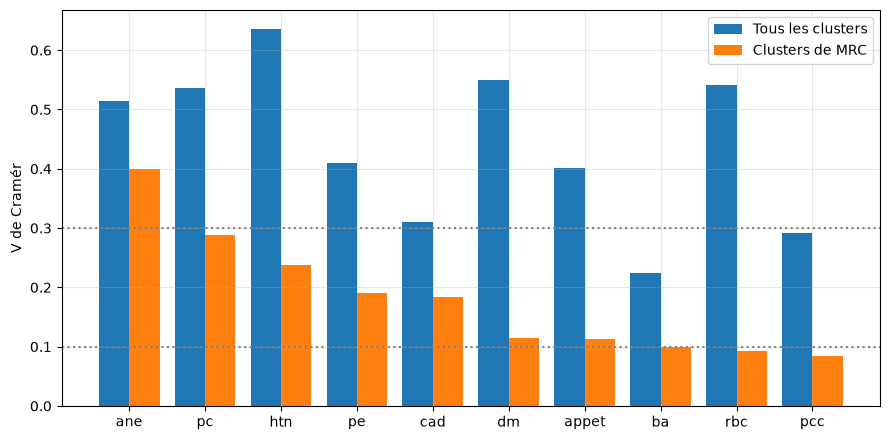

In [19]:
comp = pd.DataFrame({"V (tous les clusters)": res_tous["V de Cramér"], "V (clusters de MRC)": res_mrc["V de Cramér"]})


def role(r):
    if r["V (clusters de MRC)"] >= 0.2:
        return "marqueur de progression"
    if r["V (tous les clusters)"] >= 0.2:
        return "facteur de risque"
    return "peu discriminant"


comp["rôle"] = comp.apply(role, axis=1)
comp = comp.sort_values("V (clusters de MRC)", ascending=False)
display(comp)

fig, ax = plt.subplots(figsize=(9, 4.5))
idx = np.arange(len(comp))
ax.bar(idx - 0.2, comp["V (tous les clusters)"], 0.4, label="Tous les clusters")
ax.bar(idx + 0.2, comp["V (clusters de MRC)"], 0.4, label="Clusters de MRC")
ax.set_xticks(idx)
ax.set_xticklabels(comp.index)
ax.axhline(0.1, color="grey", ls=":")
ax.axhline(0.3, color="grey", ls=":")
ax.set_ylabel("V de Cramér")
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 Classement par forêt aléatoire

Exactitude en validation croisée : tous les clusters = 0.77 ; clusters de MRC = 0.72


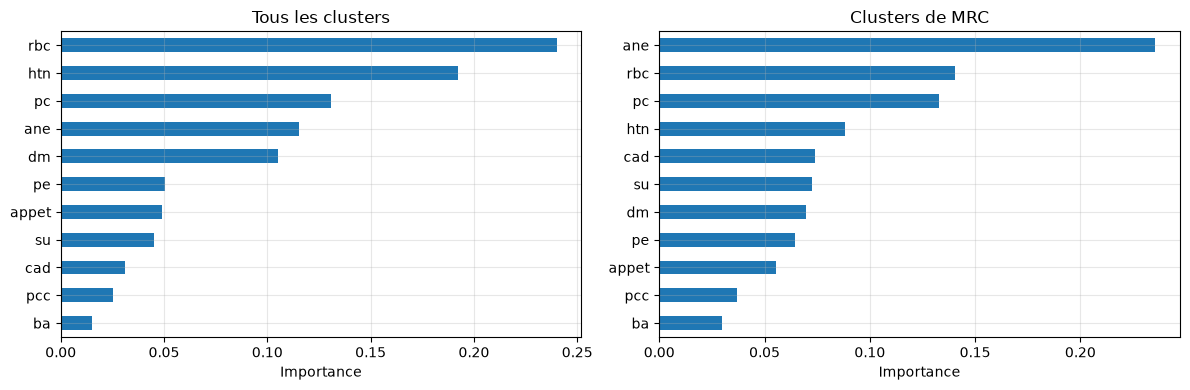

In [20]:
EXPL = CAT + ["su"]


def importance_rf(data):
    X = data[EXPL].copy()
    X[CAT] = X[CAT].fillna("unknown")          # rbc et pc : l'absence d'information est conservée comme modalité
    X = pd.get_dummies(X, columns=CAT, dtype=float)
    y = data["groupe"]
    rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced",
                                random_state=SEED, n_jobs=-1)
    acc = cross_val_score(rf, X, y, cv=min(5, int(y.value_counts().min()))).mean()
    rf.fit(X, y)
    imp = pd.Series(rf.feature_importances_, index=X.columns).groupby(lambda c: c.split("_")[0]).sum()
    return imp.sort_values(ascending=False), acc


imp_tous, acc_tous = importance_rf(tous)
imp_mrc, acc_mrc = importance_rf(mrc)
print(f"Exactitude en validation croisée : tous les clusters = {acc_tous:.2f} ; clusters de MRC = {acc_mrc:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, imp, titre in zip(axes, [imp_tous, imp_mrc], ["Tous les clusters", "Clusters de MRC"]):
    imp.sort_values().plot.barh(ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

### 4.3 Patients non atteints : glycémie et pression artérielle

Chez les patients non atteints (`notckd`), on décrit la plage observée de la glycémie aléatoire (`bgr`) et de la pression artérielle (`bp`). Un seuil séparant malades et non-malades est ensuite estimé par l'indice de Youden sur la courbe ROC (il maximise sensibilité + spécificité − 1) et par un arbre de décision de profondeur 1. Ces seuils sont comparés aux repères cliniques usuels : glycémie aléatoire de 200 mg/dL et pression diastolique de 90 mm Hg.

,bgr,bp
count,150.0,150.0
mean,107.9,71.4
std,18.4,8.5
min,70.0,60.0
5%,78.4,60.0
50%,107.5,70.0
95%,133.5,80.0
max,140.0,80.0


Non-malades au-dessus des repères cliniques : glycémie >= 200 : 0.0 % ; pression >= 90 : 0.0 %


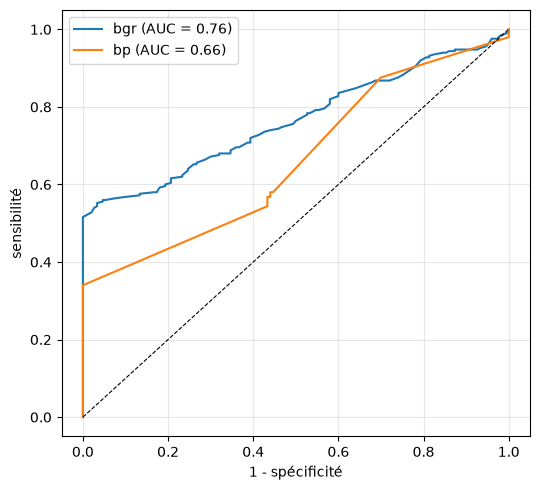

,AUC,seuil (Youden),sensibilité,spécificité,seuil (arbre)
variable,,,,,
bgr,0.764,137.1,0.55,0.97,140.4
bp,0.662,83.4,0.34,1.00,81.7


In [21]:
sains = df[df["classification"] == "notckd"]
display(sains[["bgr", "bp"]].describe(percentiles=[0.05, 0.5, 0.95]).round(1))
part_g = 100 * (sains["bgr"] >= 200).mean()
part_p = 100 * (sains["bp"] >= 90).mean()
print(f"Non-malades au-dessus des repères cliniques : glycémie >= 200 : {part_g:.1f} % ; pression >= 90 : {part_p:.1f} %")

y = (df["classification"] == "ckd").astype(int)
res_roc = []
fig, ax = plt.subplots(figsize=(5.5, 5))
for v in ["bgr", "bp"]:
    fpr, tpr, thr = roc_curve(y, df[v])
    j = np.argmax(tpr - fpr)
    arbre = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(df[[v]], y).tree_.threshold[0]
    auc = roc_auc_score(y, df[v])
    res_roc.append({"variable": v, "AUC": round(auc, 3), "seuil (Youden)": round(thr[j], 1),
                    "sensibilité": round(tpr[j], 2), "spécificité": round(1 - fpr[j], 2),
                    "seuil (arbre)": round(arbre, 1)})
    ax.plot(fpr, tpr, label=f"{v} (AUC = {auc:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("1 - spécificité")
ax.set_ylabel("sensibilité")
ax.legend()
plt.tight_layout()
plt.show()
res_roc = pd.DataFrame(res_roc).set_index("variable")
res_roc

### 4.4 Conclusions

In [22]:
LIBC = {"htn": "l'hypertension", "dm": "le diabète", "cad": "la maladie coronarienne", "ane": "l'anémie",
        "pe": "l'œdème des pieds", "appet": "l'altération de l'appétit", "rbc": "les globules rouges urinaires",
        "pc": "les cellules de pus", "pcc": "les agrégats de cellules de pus", "ba": "les bactéries urinaires",
        "su": "le sucre urinaire"}


def avec_v(lst, col):
    return liste([f"{LIBC[c]} (V = {f(comp.loc[c, col], 2)})" for c in lst])


risque = comp.index[comp["rôle"] == "facteur de risque"].tolist()
prog = comp.index[comp["rôle"] == "marqueur de progression"].tolist()
neutre = comp.index[comp["rôle"] == "peu discriminant"].tolist()
out = []
if risque:
    out.append("**Facteurs de risque.** " + cap(avec_v(risque, "V (tous les clusters)")) +
               " : lien marqué entre malades et non-malades, mais inférieur à 0,2 entre les clusters de MRC. "
               f"{'Ces variables sont associées' if len(risque) > 1 else 'Cette variable est associée'} "
               "à la présence de la maladie plutôt qu'à son niveau de sévérité.")
if prog:
    out.append("**Marqueurs de progression.** " + cap(avec_v(prog, "V (clusters de MRC)")) +
               " : lien qui persiste entre les clusters de MRC (V ≥ 0,2). "
               f"{'Ces variables évoluent' if len(prog) > 1 else 'Cette variable évolue'} "
               "avec la sévérité de l'atteinte rénale et traduisent la progression de la maladie.")
if neutre:
    out.append("**Variables peu discriminantes.** " + cap(liste([LIBC[c] for c in neutre])) +
               " : lien faible avec les clusters dans les deux comparaisons (V < 0,2).")
if max(e_t, e_m) < 0.06:
    out.append("Le sucre urinaire ne différencie pas les clusters (ε² < 0,06).")
else:
    out.append(f"Le sucre urinaire varie avec les clusters (ε² = {f(e_t, 2)} entre tous les clusters, {f(e_m, 2)} entre les clusters de MRC).")
nom_t = liste([LIBC.get(c, c) for c in imp_tous.index[:3]])
nom_m = liste([LIBC.get(c, c) for c in imp_mrc.index[:3]])
out.append(f"Le classement par forêt aléatoire place en tête, entre tous les clusters : {nom_t} "
           f"(exactitude de {f(acc_tous, 2)}), et entre les clusters de MRC : {nom_m} "
           f"(exactitude de {f(acc_mrc, 2)}).")
out.append(f"Chez les non-malades, la glycémie aléatoire reste généralement inférieure à 200 mg/dL ({f(100 - part_g, 0)} % des cas) "
           f"et la pression artérielle à 90 mm Hg ({f(100 - part_p, 0)} % des cas). Le seuil de Youden est de "
           f"{f(res_roc.loc['bgr', 'seuil (Youden)'], 0)} mg/dL pour la glycémie (AUC = {f(res_roc.loc['bgr', 'AUC'], 2)}) et de "
           f"{f(res_roc.loc['bp', 'seuil (Youden)'], 0)} mm Hg pour la pression (AUC = {f(res_roc.loc['bp', 'AUC'], 2)}).")
for o in out:
    display(Markdown(o))

**Facteurs de risque.** L'œdème des pieds (V = 0,41), la maladie coronarienne (V = 0,31), le diabète (V = 0,55), l'altération de l'appétit (V = 0,40), les bactéries urinaires (V = 0,23), les globules rouges urinaires (V = 0,54) et les agrégats de cellules de pus (V = 0,29) : lien marqué entre malades et non-malades, mais inférieur à 0,2 entre les clusters de MRC. Ces variables sont associées à la présence de la maladie plutôt qu'à son niveau de sévérité.

**Marqueurs de progression.** L'anémie (V = 0,40), les cellules de pus (V = 0,29) et l'hypertension (V = 0,24) : lien qui persiste entre les clusters de MRC (V ≥ 0,2). Ces variables évoluent avec la sévérité de l'atteinte rénale et traduisent la progression de la maladie.

Le sucre urinaire varie avec les clusters (ε² = 0,15 entre tous les clusters, 0,00 entre les clusters de MRC).

Le classement par forêt aléatoire place en tête, entre tous les clusters : les globules rouges urinaires, l'hypertension et les cellules de pus (exactitude de 0,77), et entre les clusters de MRC : l'anémie, les globules rouges urinaires et les cellules de pus (exactitude de 0,72).

Chez les non-malades, la glycémie aléatoire reste généralement inférieure à 200 mg/dL (100 % des cas) et la pression artérielle à 90 mm Hg (100 % des cas). Le seuil de Youden est de 137 mg/dL pour la glycémie (AUC = 0,76) et de 83 mm Hg pour la pression (AUC = 0,66).

### 4.5 Ce qu'on retient

**Les profils (consigne 1).** Les patients se répartissent en trois niveaux de gravité croissante. Le cluster 1 (158 patients, 6 % classés MRC) a un bilan rénal conservé : créatinine de 0,9 mg/dL, hémoglobine de 15 g/dL. Le cluster 2 (162 patients, 99 % de MRC) correspond à une atteinte modérée : créatinine de 1,8 mg/dL, urée de 46 mg/dL, hémoglobine de 11,6 g/dL. Le cluster 3 (80 patients, 100 % de MRC) correspond à une atteinte sévère : créatinine de 6,35 mg/dL, urée de 107 mg/dL, hémoglobine de 9,1 g/dL.

**Les déterminants (consigne 2).**

1. **L'anémie est le marqueur de progression le plus net** (V = 0,40). Son lien avec le cluster persiste entre l'atteinte modérée et l'atteinte sévère, et elle arrive en tête du classement de la forêt aléatoire entre les clusters de MRC.
2. **L'hypertension et les cellules de pus** évoluent aussi avec la sévérité, avec un lien plus modeste (V = 0,24 et 0,29). L'hypertension n'est donc pas seulement une cause connue de la MRC : elle devient plus fréquente à mesure que l'atteinte s'aggrave.
3. **Le diabète** (V = 0,55), **la maladie coronarienne** (V = 0,31) et **le sucre urinaire** (ε² = 0,15 entre tous les clusters, 0,00 entre les clusters de MRC) distinguent les patients atteints des non-atteints, mais ne varient plus entre l'atteinte modérée et l'atteinte sévère. Ils sont déjà en place dès l'atteinte modérée, ce qui est cohérent avec le rôle de cause connue de la MRC pour le diabète et la maladie coronarienne.
4. **L'œdème des pieds** (V = 0,41) **et l'altération de l'appétit** (V = 0,40) sont fortement associés à la maladie, mais ne distinguent pas l'atteinte modérée de l'atteinte sévère (V < 0,2). Ils apparaissent dès l'atteinte modérée : dans cet échantillon, ils signalent la maladie sans mesurer sa gravité.
5. **Les marqueurs urinaires** (globules rouges anormaux, V = 0,54 ; agrégats de cellules de pus, V = 0,29 ; bactéries, V = 0,23) distinguent les malades des non-malades sans séparer les deux niveaux de MRC.

Le schéma de départ (c'est à dire les causes présentes tôt et qui s'aggravent) est donc confirmé pour le diabète, la maladie coronarienne et l'anémie. Il est nuancé pour l'hypertension, qui progresse aussi avec la sévérité, et pour l'œdème et l'appétit, qui sont présents dès l'atteinte modérée.

**Les patients non atteints.** Aucun ne dépasse 200 mg/dL de glycémie ni 90 mm Hg de pression artérielle. Le seuil qui sépare le mieux malades et non-malades est de 137 mg/dL pour la glycémie (AUC = 0,76, séparation moyenne) et de 83 mm Hg pour la pression (AUC = 0,66, séparation faible).

**Précautions de lecture.**Les globules rouges urinaires et les cellules de pus, qui ressortent dans la forêt aléatoire, comportent beaucoup de valeurs manquantes (38 % et 16 %) : leur importance peut refléter les conditions de recueil des données plus que la biologie.

## 5. Limites

- Les clusters sont des profils statistiques ordonnés par sévérité. Ils ne correspondent pas aux stades officiels de la MRC, qui reposent sur le débit de filtration glomérulaire : celui-ci n'est pas calculable ici, le sexe n'étant pas renseigné.
- Les variables numériques ont été imputées avant l'analyse (valeurs non entières pour le sodium, le potassium ou les globules rouges), ce qui peut au contraire accentuer les écarts entre clusters, puisque l'imputation est guidée par la classe. `rbc` et `pc` comportent beaucoup de valeurs manquantes.
- Quelques observations sont atypiques (créatinine ou urée incohérentes) ; elles n'influencent pas les clusters (voir 2.4).
- La silhouette est modérée : la sévérité forme un continuum et les frontières entre clusters sont en partie conventionnelles.
- Les liens et importances mesurés sont descriptifs ; ils n'établissent pas de relation causale. La forêt aléatoire, l'exactitude et les AUC sont utilisées uniquement à des fins descriptives ; le projet ne construit pas de modèle prédictif.